# Bagian E2: Naïve Bayes untuk Data Teks (Deteksi SMS Spam)

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmad-fathan/Fundamentals-of-Data-Science/blob/main/Classification/bab-e2-naive-bayes-data-teks.ipynb)

Bagian ini menerapkan **Multinomial Naïve Bayes** pada data teks. Tugasnya adalah membedakan SMS spam dari SMS biasa. Kita akan:

1. memuat dan mengenal dataset SMS,
2. membagi data latih dan data uji **sebelum** teks diolah, agar tidak terjadi kebocoran data,
3. mengubah teks menjadi angka dengan *bag of words* (`CountVectorizer`),
4. melatih model dan melihat kata-kata yang paling menandakan spam,
5. mengevaluasi model dan memahami jenis kesalahannya,
6. melihat pengaruh Laplace smoothing (`alpha`) dan memprediksi SMS baru.

Bagian ini melanjutkan Bagian E1. Jalankan cell secara berurutan dari atas ke bawah. Perkiraan waktu: 45 sampai 60 menit.

## E2.1 Mengimpor Library

In [1]:
%matplotlib inline
import numpy as np                      # komputasi numerik
import pandas as pd                     # tabel data (DataFrame)
import matplotlib.pyplot as plt         # visualisasi

from sklearn.model_selection import train_test_split            # membagi data latih dan uji
from sklearn.feature_extraction.text import CountVectorizer     # teks -> hitungan kata
from sklearn.naive_bayes import MultinomialNB                   # Naive Bayes untuk hitungan kata
from sklearn.pipeline import make_pipeline                      # merangkai vektorisasi + model
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

print("Library berhasil diimpor")

Library berhasil diimpor


## E2.2 Mengenal Dataset SMS

Dataset yang dipakai adalah **SMS Spam Collection** (Almeida dan Hidalgo, 2011), berisi 5.572 SMS berbahasa Inggris. Setiap SMS diberi label:

- `ham` = SMS biasa (bukan spam)
- `spam` = SMS spam, misalnya iklan, undian palsu, atau penipuan

In [2]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
sms = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print("Ukuran data:", sms.shape)
sms.head()

Ukuran data: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
jumlah = sms["label"].value_counts()
print(jumlah)
print()
print((jumlah / len(sms)).round(3))

label
ham     4825
spam     747
Name: count, dtype: int64

label
ham     0.866
spam    0.134
Name: count, dtype: float64


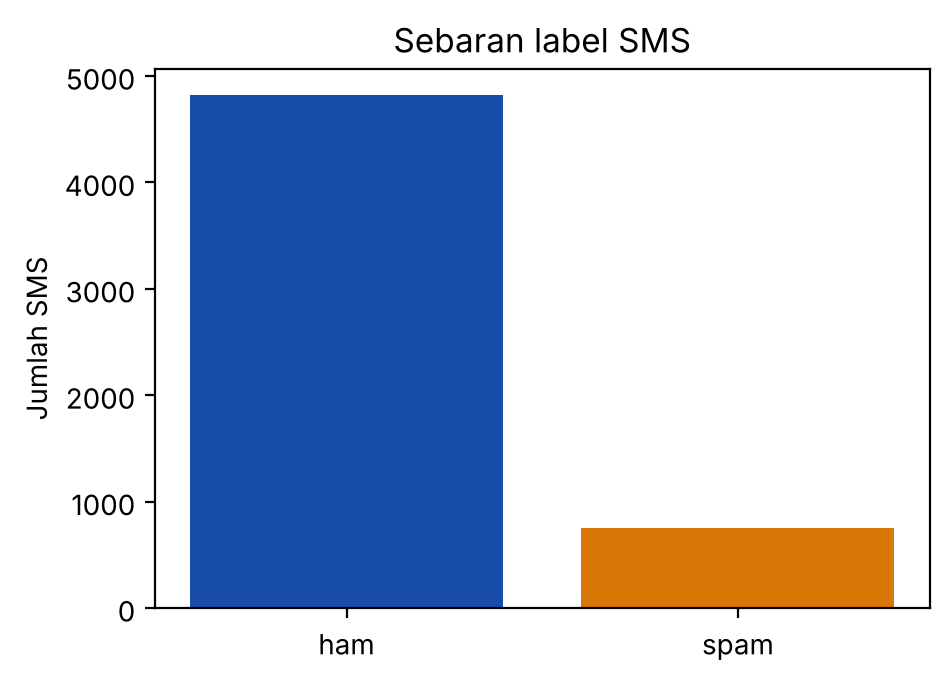

In [4]:
plt.figure(figsize=(5, 3.5))
plt.bar(jumlah.index, jumlah.values, color=["#174CAA", "#D97706"])
plt.ylabel("Jumlah SMS")
plt.title("Sebaran label SMS")
plt.show()

Hanya sekitar 13 persen SMS yang berlabel spam. Data seperti ini disebut **tidak seimbang** (*imbalanced*). Akibatnya, akurasi saja tidak cukup untuk menilai model. Model yang selalu menjawab `ham` sudah benar sekitar 87 persen, padahal tidak pernah menemukan satu spam pun. Karena itu, di E2.6 kita juga melihat *precision* dan *recall* untuk kelas spam.

Berikut beberapa contoh SMS spam:

In [5]:
for pesan in sms.loc[sms["label"] == "spam", "message"].head(4):
    print("-", pesan)

- Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
- FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
- WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
- Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030


## E2.3 Membagi Data Sebelum Mengolah Teks

Pada data teks, urutan langkah sangat penting. Data harus **dibagi lebih dulu**, baru kemudian kosakata dibangun dari data latih saja.

Jika kosakata dibangun dari seluruh data sebelum dibagi, model sudah "mengintip" kata-kata dari data uji. Kesalahan ini disebut **kebocoran data** (*data leakage*). Akibatnya, hasil evaluasi menjadi terlalu bagus dan tidak mencerminkan kinerja model pada SMS yang benar-benar baru.

Parameter `stratify` menjaga proporsi spam tetap sekitar 13 persen di kedua bagian.

In [6]:
X = sms["message"]     # teks SMS
y = sms["label"]       # ham atau spam

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Data latih:", len(X_train), "| data uji:", len(X_test))
print("Proporsi spam di data latih:", round((y_train == "spam").mean(), 3))
print("Proporsi spam di data uji  :", round((y_test == "spam").mean(), 3))

Data latih: 4457 | data uji: 1115
Proporsi spam di data latih: 0.134
Proporsi spam di data uji  : 0.134


## E2.4 Dari Teks ke Angka: *Bag of Words*

Model tidak dapat membaca kalimat. Teks perlu diubah menjadi angka dengan cara yang sama seperti di modul: setiap kata menjadi satu fitur, dan nilai fiturnya adalah **berapa kali kata itu muncul** dalam sebuah SMS. Cara ini disebut *bag of words*.

`CountVectorizer` melakukan tiga hal sekaligus:

- mengubah semua huruf menjadi huruf kecil,
- memecah kalimat menjadi kata-kata,
- membuang *stop words*, yaitu kata umum seperti *the*, *is*, dan *to* yang tidak membantu membedakan spam.

Kita coba dulu pada tiga SMS kecil agar hasilnya mudah dilihat.

In [7]:
contoh = [
    "FREE prize! Claim your free prize now",
    "Are we still meeting for lunch?",
    "Free lunch at the meeting today",
]

vec_contoh = CountVectorizer(stop_words="english")
matriks = vec_contoh.fit_transform(contoh)

pd.DataFrame(matriks.toarray(), columns=vec_contoh.get_feature_names_out(),
             index=["SMS 1", "SMS 2", "SMS 3"])

,claim,free,lunch,meeting,prize,today
SMS 1,1,2,0,0,2,0
SMS 2,0,0,1,1,0,0
SMS 3,0,1,1,1,0,1


Setiap baris adalah satu SMS dan setiap kolom adalah satu kata. Pada SMS 1, kata `free` dan `prize` masing-masing muncul 2 kali. Huruf besar dan kecil dianggap sama, sedangkan kata seperti *your*, *now*, dan *are* terbuang karena termasuk *stop words*.

Pada data sebenarnya, jumlah kolomnya mencapai ribuan kata. Hampir semua sel bernilai 0, karena setiap SMS hanya memuat sedikit kata dari seluruh kosakata.

## E2.5 Melatih Model Multinomial Naïve Bayes

Multinomial Naïve Bayes menghitung likelihood sebuah SMS dari probabilitas setiap kata yang muncul di dalamnya:

$$P(X \mid y) \propto \prod_{i=1}^{n} \theta_{y,i}^{\,x_i} \tag{1}$$

**Keterangan:**

- $P(X \mid y)$ = likelihood SMS $X$ pada kelas $y$
- $\theta_{y,i}$ = probabilitas kata ke-$i$ pada kelas $y$
- $x_i$ = berapa kali kata ke-$i$ muncul dalam SMS
- $n$ = banyaknya kata dalam kosakata
- $\propto$ = sebanding dengan

Probabilitas setiap kata ditaksir dari data latih dengan Laplace smoothing:

$$\theta_{y,i} = \frac{N_{y,i} + \alpha}{N_y + \alpha n} \tag{2}$$

**Keterangan:**

- $\theta_{y,i}$ = probabilitas kata ke-$i$ pada kelas $y$
- $N_{y,i}$ = berapa kali kata ke-$i$ muncul di seluruh SMS kelas $y$
- $N_y$ = jumlah seluruh kata pada kelas $y$
- $\alpha$ = parameter smoothing; $\alpha = 1$ sama dengan Laplace smoothing di modul
- $n$ = banyaknya kata dalam kosakata

`make_pipeline` merangkai `CountVectorizer` dan `MultinomialNB` menjadi satu model. Saat `fit()` dipanggil, kosakata dibangun **hanya dari data latih**. Saat `predict()` dipanggil, data uji diubah memakai kosakata yang sama. Dengan begitu, kebocoran data otomatis tercegah.

In [8]:
model = make_pipeline(
    CountVectorizer(stop_words="english"),
    MultinomialNB(alpha=1.0),
)
model.fit(X_train, y_train)

vectorizer = model.named_steps["countvectorizer"]
nb = model.named_steps["multinomialnb"]
print("Banyaknya kata dalam kosakata:", len(vectorizer.vocabulary_))
print("Kelas:", nb.classes_)

Banyaknya kata dalam kosakata: 7403
Kelas: ['ham' 'spam']


### Apa yang dipelajari model?

Seperti pada Bagian E1, model hanya menyimpan hasil hitungan. Pertama, **prior** setiap kelas:

In [9]:
prior = pd.Series(np.exp(nb.class_log_prior_), index=nb.classes_, name="prior")
prior.round(3)

ham     0.866
spam    0.134
Name: prior, dtype: float64

Kedua, **probabilitas setiap kata** pada setiap kelas, yaitu $\theta_{y,i}$ pada Persamaan 2. Untuk mencari kata yang paling menandakan spam, kita bandingkan probabilitas sebuah kata di kelas spam dengan probabilitasnya di kelas ham. Semakin besar rasionya, semakin kuat kata itu menunjukkan spam.

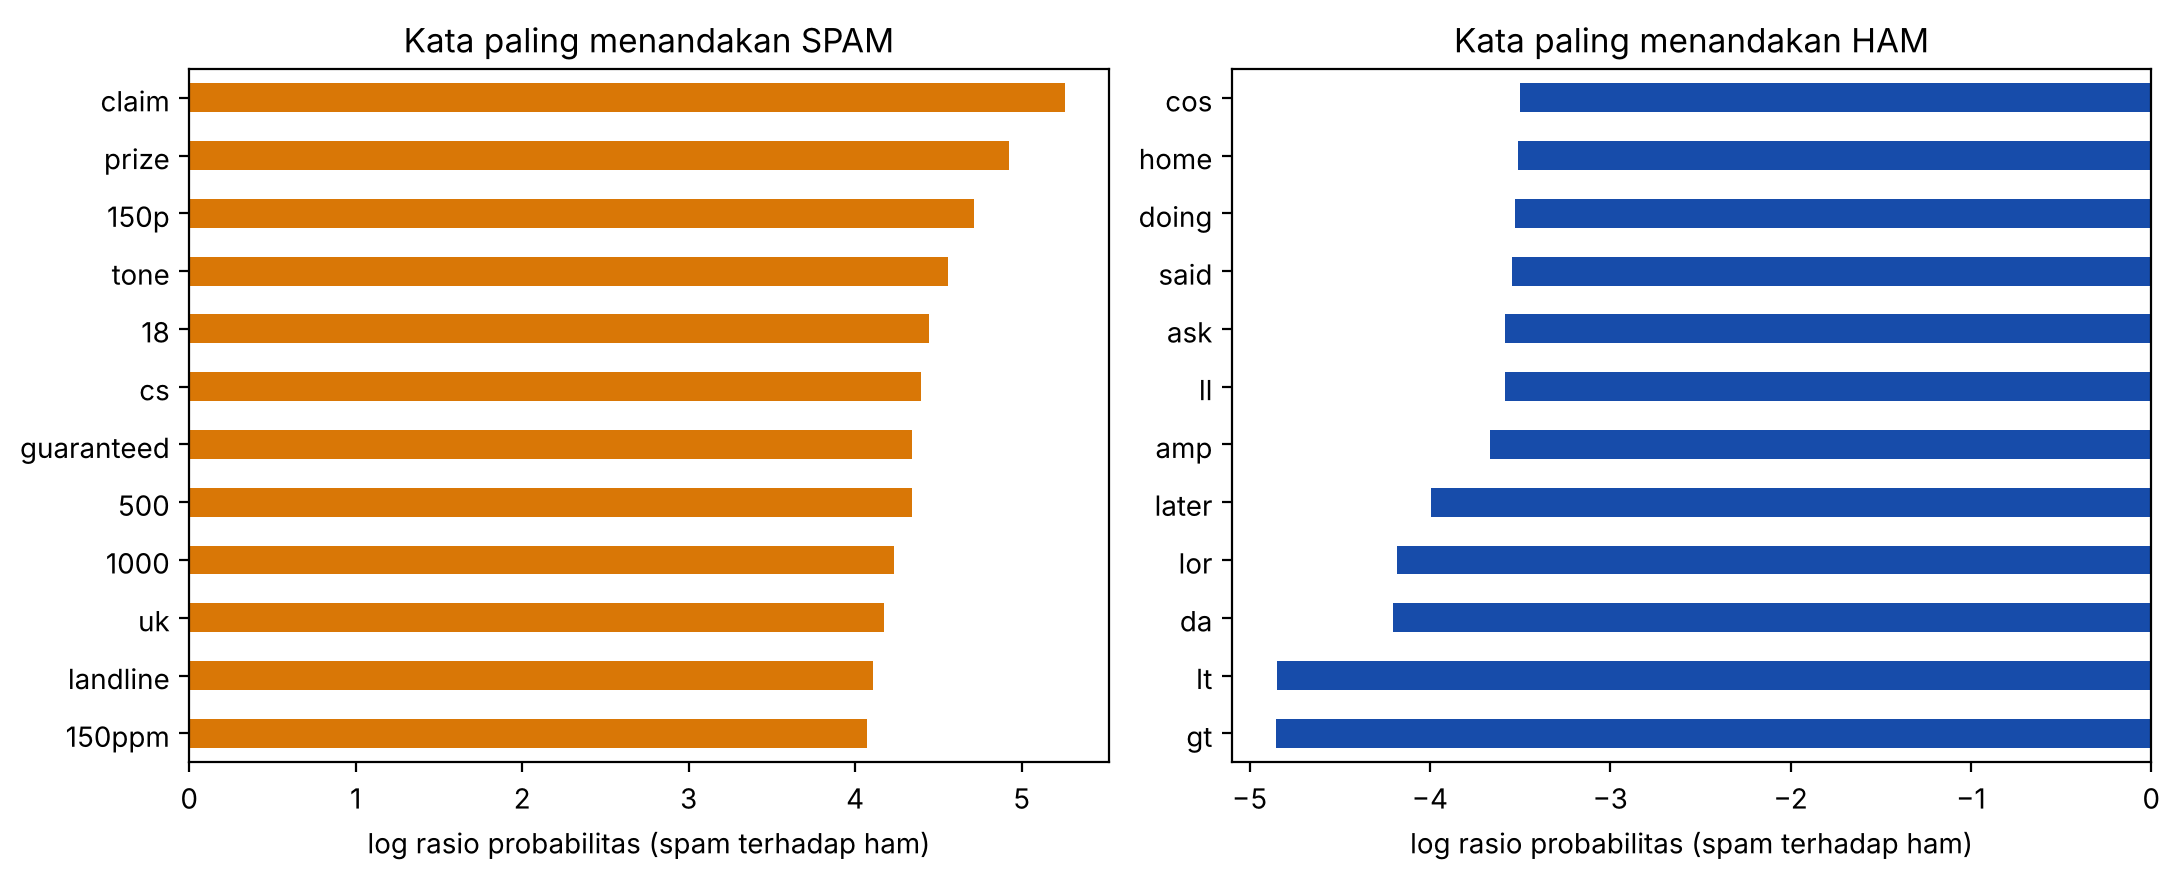

In [10]:
kata = vectorizer.get_feature_names_out()
log_prob = pd.DataFrame(nb.feature_log_prob_, index=nb.classes_, columns=kata)

# log rasio: positif berarti lebih sering di spam, negatif berarti lebih sering di ham
log_rasio = (log_prob.loc["spam"] - log_prob.loc["ham"]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
log_rasio.tail(12).plot.barh(ax=axes[0], color="#D97706")
axes[0].set_title("Kata paling menandakan SPAM")
log_rasio.head(12).plot.barh(ax=axes[1], color="#174CAA")
axes[1].set_title("Kata paling menandakan HAM")
for ax in axes:
    ax.set_xlabel("log rasio probabilitas (spam terhadap ham)")
plt.tight_layout()
plt.show()

Kata-kata spam seperti *claim*, *prize*, *guaranteed*, dan *tone* (nada dering) adalah ciri khas undian palsu dan layanan berbayar. Kata *150p* dan *150ppm* adalah tarif SMS berbayar (150 pence per pesan atau per menit), dan *18* biasanya muncul dari keterangan "khusus usia 18 tahun ke atas". Kata-kata ham seperti *lor*, *da*, *later*, dan *home* adalah bahasa percakapan sehari-hari (beberapa di antaranya bahasa gaul Singapura, tempat sebagian SMS dikumpulkan). Model mempelajari pola ini hanya dengan menghitung kata.

Kata *gt* dan *lt* di grafik ham bukan kata sungguhan. Keduanya berasal dari kode `&lt;` dan `&gt;` yang tertinggal di teks SMS ham. Model tetap memanfaatkannya karena kode itu memang hanya muncul di ham. Ini mengingatkan bahwa data teks sebaiknya diperiksa dan dibersihkan dulu sebelum dipakai.

## E2.6 Mengevaluasi Model

In [11]:
y_pred = model.predict(X_test)

print(f"Akurasi data uji: {accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, digits=3))

Akurasi data uji: 0.985



              precision    recall  f1-score   support

         ham      0.988     0.995     0.991       966
        spam      0.965     0.919     0.942       149

    accuracy                          0.985      1115
   macro avg      0.976     0.957     0.966      1115
weighted avg      0.985     0.985     0.985      1115



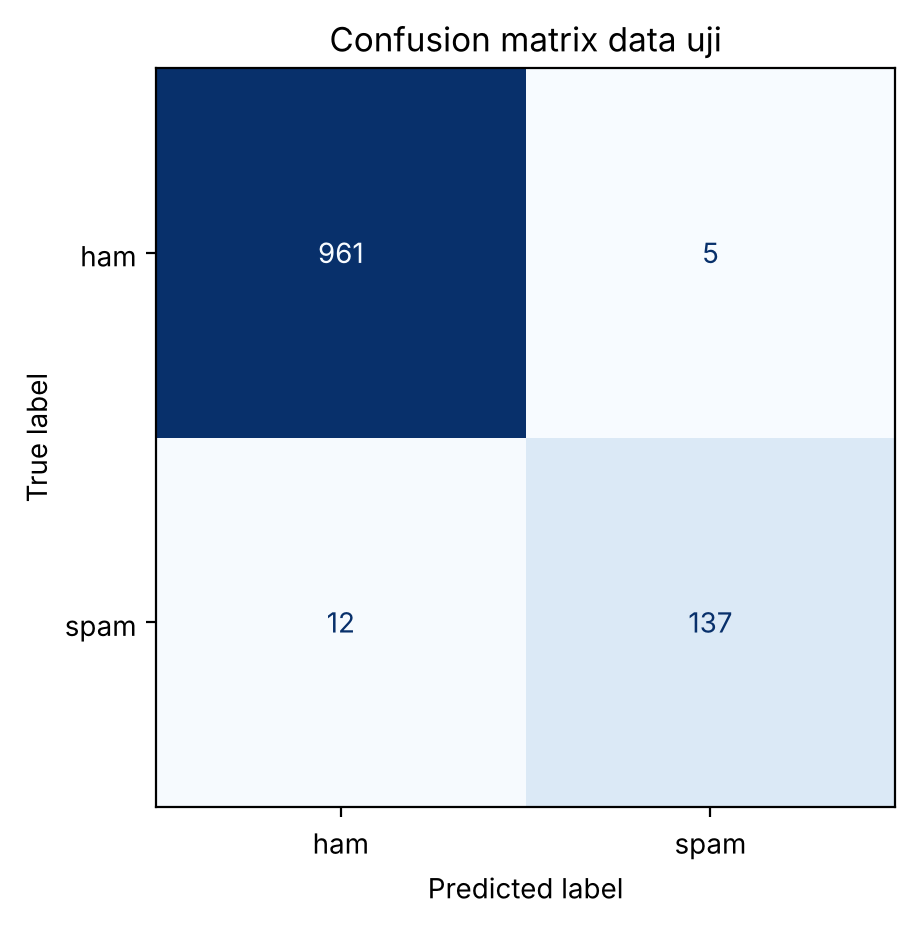

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

disp = ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"])
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix data uji")
plt.show()

Akurasinya sekitar 98,5 persen, jauh di atas model "selalu ham" yang hanya 87 persen. Untuk kelas spam, perhatikan dua angka berikut:

- **Precision spam** (sekitar 0,96): dari semua SMS yang ditandai spam, berapa yang benar-benar spam. Kesalahannya adalah SMS biasa yang ikut masuk folder spam (baris `ham`, kolom `spam`).
- **Recall spam** (sekitar 0,92): dari semua spam yang sebenarnya, berapa yang berhasil ditangkap. Kesalahannya adalah spam yang lolos ke kotak masuk (baris `spam`, kolom `ham`).

Bagi pengguna, SMS penting yang salah masuk folder spam biasanya lebih merugikan daripada satu spam yang lolos. Karena itu, pada filter spam, precision yang tinggi sering lebih diutamakan.

Beberapa contoh spam yang lolos dapat membantu memahami keterbatasan model:

In [13]:
lolos = X_test[(y_test == "spam") & (y_pred == "ham")]
for pesan in lolos.head(4):
    print("-", pesan)

- ringtoneking 84484
- Sorry I missed your call let's talk when you have the time. I'm on 07090201529
- Latest News! Police station toilet stolen, cops have nothing to go on!
- Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Calls£1/minmoremobsEMSPOBox45PO139WA


Spam yang lolos biasanya pendek atau memakai kata-kata percakapan biasa, sehingga hitungan katanya mirip SMS ham.

## E2.7 Pengaruh Laplace Smoothing (`alpha`)

Di modul, Laplace smoothing mencegah satu nilai yang tidak pernah muncul membuat seluruh skor bernilai nol. Masalah yang sama terjadi pada teks: ada kata yang muncul di SMS ham tetapi **tidak pernah** muncul di SMS spam pada data latih.

Kita cari kata seperti itu, lalu masukkan ke dalam sebuah SMS yang jelas-jelas spam.

In [14]:
hitung = pd.DataFrame(nb.feature_count_, index=nb.classes_, columns=kata)

# kata (huruf saja, minimal 4 huruf) yang sering di ham tetapi 0 kali di spam
nol_di_spam = hitung.loc["ham"][hitung.loc["spam"] == 0]
nol_di_spam = nol_di_spam[[k.isalpha() and len(k) >= 4 for k in nol_di_spam.index]]
print(nol_di_spam.sort_values(ascending=False).head(8).astype(int))

later      109
said        69
doing       68
really      63
morning     61
sure        55
went        52
nice        51
Name: ham, dtype: int64


Kata *later* muncul lebih dari 100 kali di SMS ham, tetapi tidak pernah di SMS spam. Sekarang kita buat SMS bernada spam yang diakhiri kata *later*. Kata-kata spam lainnya (*urgent*, *free*, *cash*, *award*, *win*, dan seterusnya) sengaja dipilih dari kata yang pernah muncul di kedua kelas, supaya pengaruh kata *later* terlihat jelas.

In [15]:
sms_uji = "URGENT! You have been selected to receive a FREE cash award. Txt WIN now, see you later"
print("Kata yang dibaca model:", vectorizer.build_analyzer()(sms_uji))
print("Hitungan kata 'later'  :", hitung["later"].astype(int).to_dict())
print()

for a in [1e-10, 1.0]:
    m = make_pipeline(CountVectorizer(stop_words="english"), MultinomialNB(alpha=a, force_alpha=True))
    m.fit(X_train, y_train)
    p_spam = m.predict_proba([sms_uji])[0][list(m.classes_).index("spam")]
    print(f"alpha = {a:<6g} -> prediksi: {m.predict([sms_uji])[0]:4s} | P(spam) = {p_spam:.3f}")

Kata yang dibaca model: ['urgent', 'selected', 'receive', 'free', 'cash', 'award', 'txt', 'win', 'later']
Hitungan kata 'later'  : {'ham': 109, 'spam': 0}

alpha = 1e-10  -> prediksi: ham  | P(spam) = 0.061
alpha = 1      -> prediksi: spam | P(spam) = 1.000


Tanpa smoothing (`alpha` hampir nol), probabilitas kata *later* di kelas spam hampir nol. Satu kata itu sudah cukup untuk menjatuhkan skor spam, sehingga SMS yang jelas-jelas spam diprediksi ham dengan P(spam) hanya sekitar 0,06. Dengan `alpha = 1`, kata *later* hanya sedikit menurunkan skor spam, dan prediksinya kembali benar. Ini adalah masalah probabilitas nol yang sama dengan contoh Overcast di modul.

Nilai `alpha` juga dapat dicoba beberapa kali untuk melihat pengaruhnya pada kinerja:

In [16]:
hasil = []
for a in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]:
    m = make_pipeline(CountVectorizer(stop_words="english"), MultinomialNB(alpha=a))
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    hasil.append({"alpha": a,
                  "akurasi": accuracy_score(y_test, pred),
                  "precision spam": precision_score(y_test, pred, pos_label="spam"),
                  "recall spam": recall_score(y_test, pred, pos_label="spam")})

pd.DataFrame(hasil).round(3)

,alpha,akurasi,precision spam,recall spam
0,0.01,0.983,0.958,0.913
1,0.10,0.985,0.965,0.919
2,0.50,0.985,0.958,0.926
3,1.00,0.985,0.965,0.919
4,2.00,0.984,0.971,0.906
5,5.00,0.981,0.992,0.866


Untuk `alpha` antara 0,1 dan 1, akurasinya hampir sama. Saat `alpha` makin besar, precision spam naik tetapi recall spam turun: model makin berhati-hati menandai spam, sehingga makin banyak spam yang lolos. Hal ini terjadi karena `alpha` yang besar membuat probabilitas semua kata makin mirip di kedua kelas, sehingga bukti dari kata-kata spam melemah. Nilai bawaan `alpha = 1` sudah menjadi pilihan awal yang baik.

Perlu diingat, memilih `alpha` dengan melihat data uji sebenarnya juga bentuk "mengintip". Pada proyek sungguhan, `alpha` dipilih dengan data validasi atau *cross-validation*. Tabel di atas hanya untuk memperlihatkan pengaruhnya.

## E2.8 Memprediksi SMS Baru

Karena vektorisasi dan model sudah dirangkai dalam satu *pipeline*, SMS baru cukup diberikan dalam bentuk teks biasa.

In [17]:
sms_baru = [
    "Congratulations! You have won a FREE prize. Call now to claim",
    "Hi, are we still meeting for lunch tomorrow?",
    "URGENT: your account will be suspended, reply YES to keep it active",
]

proba = model.predict_proba(sms_baru)
idx_spam = list(model.classes_).index("spam")
for pesan, label, p in zip(sms_baru, model.predict(sms_baru), proba[:, idx_spam]):
    print(f"[{label:4s}] P(spam) = {p:.3f} | {pesan}")

[spam] P(spam) = 1.000 | Congratulations! You have won a FREE prize. Call now to claim
[ham ] P(spam) = 0.000 | Hi, are we still meeting for lunch tomorrow?
[spam] P(spam) = 0.990 | URGENT: your account will be suspended, reply YES to keep it active


Silakan coba SMS buatan sendiri pada cell berikut. Di Google Colab, kolom isian akan muncul di sebelah kanan cell.

In [18]:
pesan_saya = "Your free ringtone is waiting, text TONE to 8007 to claim"  # @param {type:"string"}

p = model.predict_proba([pesan_saya])[0][idx_spam]
print("Prediksi:", model.predict([pesan_saya])[0], f"| P(spam) = {p:.3f}")

Prediksi: spam | P(spam) = 1.000


## E2.9 Latihan

Kerjakan latihan berikut di cell kosong yang tersedia. Gunakan pembagian data latih dan data uji yang sama.

**Latihan 1.** Di modul, Bernoulli Naïve Bayes hanya memperhatikan apakah sebuah kata muncul atau tidak. Ganti model dengan `BernoulliNB` (impor dari `sklearn.naive_bayes`) dan gunakan `CountVectorizer(stop_words="english", binary=True)`. Bandingkan akurasi, precision spam, dan recall spam dengan model Multinomial.

*Hasil yang diharapkan:* akurasi sekitar 0,97, sedikit di bawah Multinomial. Jelaskan mengapa informasi "berapa kali kata muncul" membantu pada data ini.

In [19]:
# Latihan 1


**Latihan 2.** Latih ulang model Multinomial **tanpa** membuang *stop words*, yaitu `CountVectorizer()` tanpa parameter. Bandingkan banyaknya kata dalam kosakata dan kinerjanya dengan model di E2.5.

*Hasil yang diharapkan:* kosakata bertambah, sedangkan kinerjanya tidak jauh berbeda. Diskusikan apakah membuang *stop words* selalu perlu.

In [20]:
# Latihan 2


**Latihan 3.** Tulis paling sedikit lima SMS buatan sendiri, campuran spam dan bukan spam. Temukan satu SMS yang diprediksi salah oleh model, lalu jelaskan penyebabnya dengan melihat kata-kata di dalamnya dan grafik kata di E2.5.

*Hasil yang diharapkan:* tabel berisi SMS, prediksi, dan P(spam), disertai penjelasan singkat untuk SMS yang salah diprediksi.

In [21]:
# Latihan 3
